# Funnel and revenue at stake

Where sessions drop out between landing and ordering, what one point of conversion at each step is worth, and whether the funnel differs by segment. Funnel window only (26 Nov 2020 – 25 Jan 2021). Tables come from `sql/03_metrics.sql`.

In [1]:
import sys
sys.path.insert(0, "scripts")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import analysis as a

pd.set_option("display.float_format", "{:,.4f}".format)
a.chart_style()
con = a.connect()
q = lambda sql: con.sql(sql).df()

In [2]:
funnel = q("SELECT * FROM funnel_overall ORDER BY step_order")
assert (funnel.sessions.diff().dropna() <= 0).all(), "a funnel bar grew"
totals = q("""SELECT COUNT(*) AS sessions, SUM(orders) AS orders, SUM(revenue_usd) AS revenue_usd,
                     AVG(has_order::INT) AS session_conversion, SUM(revenue_usd) / SUM(orders) AS aov,
                     SUM(revenue_usd) / COUNT(*) AS revenue_per_session
              FROM fact_sessions WHERE in_funnel_window""")
display(totals)
funnel

,sessions,orders,revenue_usd,session_conversion,aov,revenue_per_session
0,248669,"3,540.0000","245,147.0000",0.0129,69.2506,0.9858


,step_order,step,sessions,share_of_sessions,step_conversion,sessions_lost
0,1,Session,248669,1.0000,NaN,<NA>
1,2,View item,50255,0.2021,0.2021,198414
2,3,Add to cart,13636,0.0548,0.2713,36619
3,4,Begin checkout,6936,0.0279,0.5087,6700
4,5,Add payment info,4592,0.0185,0.6621,2344
5,6,Order,3196,0.0129,0.6960,1396


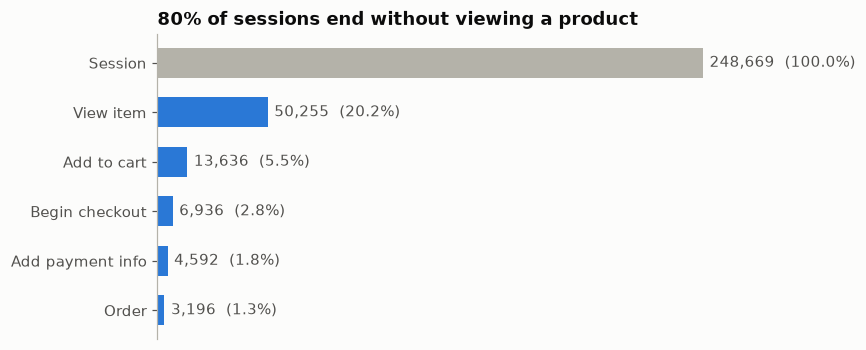

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(funnel.step[::-1], funnel.sessions[::-1], color=[a.BLUE] * 5 + [a.GRAY], height=0.6)
for y, (s, share) in enumerate(zip(funnel.sessions[::-1], funnel.share_of_sessions[::-1])):
    ax.text(s + 3000, y, f"{s:,.0f}  ({share:.1%})", va="center", color=a.MUTED)
ax.set_xlim(0, funnel.sessions.max() * 1.25)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title(f"{1 - funnel.step_conversion[1]:.0%} of sessions end without viewing a product")
fig.savefig("charts/funnel.png")

## Revenue at stake

Extra revenue per 30 days if one step converted one percentage point better and every other step stayed the same.

- **Base:** the extra sessions go on to order at the current downstream rate.
- **Low:** they order at half that rate. Marginal shoppers are usually weaker. The order step has no downstream, so its low equals its base.
- **High:** the base method on December traffic, the peak month.

In [4]:
ras = q("SELECT * FROM revenue_at_stake ORDER BY step_order")
ras[["step", "step_conversion", "drop_rate", "usd_low", "usd_base", "usd_high", "rank_by_usd", "rank_by_drop", "rank_by_sessions_lost"]]

,step,step_conversion,drop_rate,usd_low,usd_base,usd_high,rank_by_usd,rank_by_drop,rank_by_sessions_lost
0,View item,0.2021,0.7979,"2,982.8429","5,965.6858","7,295.8953",1,1,1
1,Add to cart,0.2713,0.7287,"2,221.6738","4,443.3476","5,066.3244",2,2,2
2,Begin checkout,0.5087,0.4913,"1,185.1298","2,370.2596","2,964.2168",3,3,3
3,Add payment info,0.6621,0.3379,910.5320,"1,821.0640","2,330.7890",4,4,4
4,Order,0.6960,0.3040,"1,732.2601","1,732.2601","2,159.0728",5,5,5


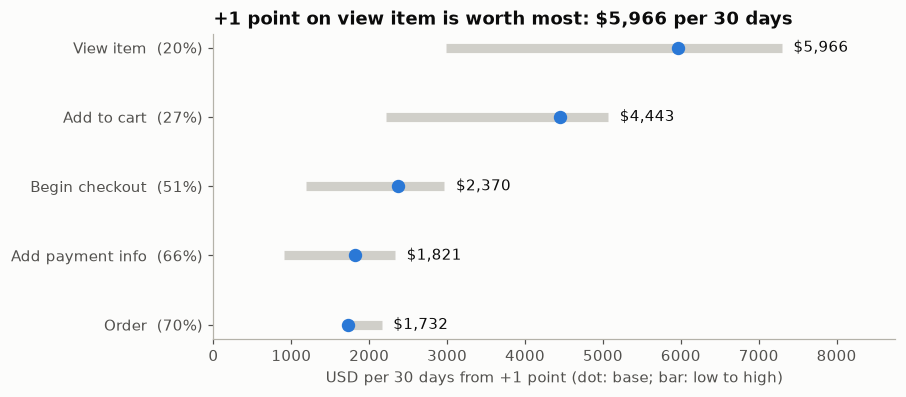

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(ras))[::-1]
ax.hlines(y, ras.usd_low, ras.usd_high, color=a.GRAY, lw=6, alpha=0.6)
ax.scatter(ras.usd_base, y, color=a.BLUE, s=60, zorder=3)
for yi, (b, lo, hi) in zip(y, ras[["usd_base", "usd_low", "usd_high"]].to_numpy()):
    ax.text(hi + 150, yi, f"${b:,.0f}", va="center", color=a.INK)
ax.set_yticks(y, [f"{s}  ({c:.0%})" for s, c in zip(ras.step, ras.step_conversion)])
ax.set_xlabel("USD per 30 days from +1 point (dot: base; bar: low to high)")
ax.set_xlim(0, ras.usd_high.max() * 1.2)
top = ras.sort_values("usd_base").iloc[-1]
ax.set_title(f"+1 point on {top.step.lower()} is worth most: ${top.usd_base:,.0f} per 30 days")
fig.savefig("charts/revenue_at_stake.png")

Under the +1 point method, a step's dollars are inversely proportional to its conversion rate, so ranking by dollars and ranking by drop rate agree by construction. Ranking by sessions lost agrees too. They only part ways once you ask how far each rate can realistically move.

A point is a 5% relative gain at product view (20% to 21%) but only 1.4% at order (70% to 71%). The ranking says where a point is worth most, not where a point is easiest to win. Product view leads in all three scenarios.

## Segments

In [6]:
seg = q("SELECT * FROM funnel_by_segment")
grown = seg.sort_values("step_order").groupby(["dimension", "segment"]).sessions.apply(lambda s: (s.diff().dropna() > 0).any())
assert not grown.any(), "a segment funnel bar grew"
seg.pivot_table(index=["dimension", "segment"], columns="step", values="step_conversion")[
    ["View item", "Add to cart", "Begin checkout", "Add payment info", "Order"]]

step                                View item  Add to cart  Begin checkout  \
dimension           segment                                                  
Device              desktop            0.2034       0.2694          0.5099   
                    mobile             0.2003       0.2746          0.5063   
                    tablet             0.1984       0.2643          0.5189   
First-touch channel Direct             0.1994       0.2725          0.5008   
                    Organic Search     0.1972       0.2539          0.4973   
                    Paid Search        0.1860       0.2510          0.4611   
                    Referral           0.2127       0.2850          0.5277   
                    Unknown            0.2079       0.2899          0.5242   
Market              India              0.2038       0.2657          0.4984   
                    Rest of world      0.2013       0.2706          0.5125   
                    United States      0.2026       0.2733          0.5068   
New vs returning    New                0.1847       0.2326          0.4435   
                    Returning          0.2532       0.3544          0.6004   

step                                Add payment info  Order  
dimension           segment                                  
Device              desktop                   0.6569 0.6881  
                    mobile                    0.6681 0.7082  
                    tablet                    0.6887 0.6827  
First-touch channel Direct                    0.6346 0.6851  
                    Organic Search            0.6429 0.6757  
                    Paid Search               0.6160 0.7397  
                    Referral                  0.7022 0.7131  
                    Unknown                   0.6865 0.7103  
Market              India                     0.6614 0.7067  
                    Rest of world             0.6673 0.6962  
                    United States             0.6566 0.6935  
New vs returning    New                       0.5106 0.6670  
                    Returning                 0.8195 0.7147

In [7]:
q("""SELECT dimension, segment, sessions, share_of_sessions AS session_conversion
     FROM funnel_by_segment WHERE step_order = 6 ORDER BY dimension, session_conversion""")

,dimension,segment,sessions,session_conversion
0,Device,desktop,1822,0.0126
1,Device,tablet,71,0.0128
2,Device,mobile,1303,0.0132
3,First-touch channel,Paid Search,108,0.0098
4,First-touch channel,Organic Search,927,0.0108
5,First-touch channel,Direct,683,0.0118
6,First-touch channel,Unknown,787,0.0154
7,First-touch channel,Referral,691,0.0160
8,Market,India,294,0.0126
9,Market,United States,1394,0.0128


Returning sessions convert at about five times the rate of new sessions and lead at every step. Device makes little difference: mobile checkout converts as well as desktop. That makes "fix mobile checkout" a weaker bet here than product discovery for new visitors.

## India vs United States

95% margins of error from the normal approximation. Sessions from one user are not independent, so these intervals are slightly too narrow. If the intervals overlap, the verdict is "no clear difference".

In [8]:
mkt = a.market_comparison(con)
mkt

,step_order,step,India_rate,United States_rate,India_moe,United States_moe,India_entering,United States_entering,verdict
0,2,View item,0.2038,0.2026,0.0052,0.0024,"23,306.0000","109,093.0000",No clear difference
1,3,Add to cart,0.2657,0.2733,0.0126,0.0059,"4,749.0000","22,100.0000",No clear difference
2,4,Begin checkout,0.4984,0.5068,0.0276,0.0126,"1,262.0000","6,040.0000",No clear difference
3,5,Add payment info,0.6614,0.6566,0.0370,0.0168,629.0000,"3,061.0000",No clear difference
4,6,Order,0.7067,0.6935,0.0437,0.0202,416.0000,"2,010.0000",No clear difference
5,7,Session conversion,0.0126,0.0128,0.0014,0.0007,"23,306.0000","109,093.0000",No clear difference


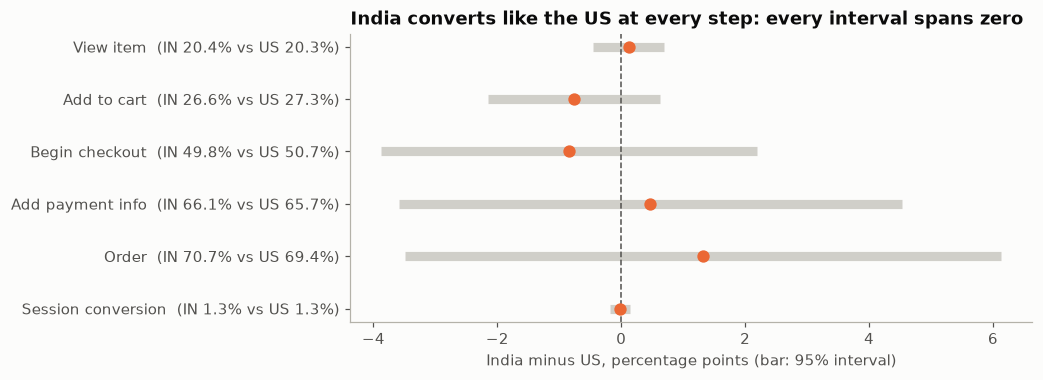

In [9]:
gap = (mkt["India_rate"] - mkt["United States_rate"]) * 100
gap_moe = np.sqrt(mkt["India_moe"] ** 2 + mkt["United States_moe"] ** 2) * 100
fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(mkt))[::-1]
ax.hlines(y, gap - gap_moe, gap + gap_moe, color=a.GRAY, lw=6, alpha=0.6)
ax.scatter(gap, y, color=a.ORANGE, s=50, zorder=3)
ax.axvline(0, color=a.MUTED, lw=1, ls="--")
ax.set_yticks(y, [f"{s}  (IN {i:.1%} vs US {u:.1%})" for s, i, u in zip(mkt.step, mkt["India_rate"], mkt["United States_rate"])])
ax.set_xlabel("India minus US, percentage points (bar: 95% interval)")
ax.set_title("India converts like the US at every step: every interval spans zero")
fig.savefig("charts/india_vs_us.png")
con.close()

India accounts for 9.4% of funnel-window sessions (23,306). At every step its interval overlaps the US one. With 416 Indian sessions reaching payment, a payment-step gap smaller than about 4 points could not be detected anyway.

The hypotheses worth testing are about the Indian buyer experience, not the conversion rate. These are hypotheses, not findings:

- prices shown in USD
- international shipping cost revealed only at checkout
- no UPI or cash-on-delivery option